# OTT Content Catalog Analytics — Netflix Titles Dataset

**Goal:** Analyze a real-world OTT (streaming) content catalog to uncover trends in content growth, genre mix, geographic sourcing, content ratings, and viewing-format patterns — the kind of analysis a Data Analyst / Data Engineer supports for content strategy and acquisition teams at an OTT platform.

**Why this project:** I work as a QA Engineer on an OTT/Media platform. This project applies the same domain knowledge to a data-analytics lens — going from *"does the feature work correctly"* to *"what does the data say about our content and platform trends."*

**Dataset:** Netflix Titles (public dataset, ~7,800 titles, TidyTuesday / Kaggle community dataset) — `show_id, type, title, director, cast, country, date_added, release_year, rating, duration, listed_in, description`.

**Tech stack:** Python (pandas, numpy) for cleaning & analysis, Matplotlib/Seaborn for visualization, SQLite + SQL for query-based analysis, and a Tableau-ready CSV export for dashboarding.

**Structure:**
1. Load & Inspect Data
2. Data Cleaning
3. Exploratory Data Analysis (Python)
4. SQL-Based Analysis (SQLite)
5. Key Insights


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3

sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 110


## 1. Load & Inspect Data

In [2]:
df = pd.read_csv('data/netflix_titles.csv')
print(f"Rows: {df.shape[0]:,}  |  Columns: {df.shape[1]}")
df.head()


Rows: 7,787  |  Columns: 12


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,TV Show,3%,NaN,"João Miguel, Bianca Comparato, Michel Gomes, R...",Brazil,"August 14, 2020",2020,TV-MA,4 Seasons,"International TV Shows, TV Dramas, TV Sci-Fi &...",In a future where the elite inhabit an island ...
1,s2,Movie,7:19,Jorge Michel Grau,"Demián Bichir, Héctor Bonilla, Oscar Serrano, ...",Mexico,"December 23, 2016",2016,TV-MA,93 min,"Dramas, International Movies",After a devastating earthquake hits Mexico Cit...
2,s3,Movie,23:59,Gilbert Chan,"Tedd Chan, Stella Chung, Henley Hii, Lawrence ...",Singapore,"December 20, 2018",2011,R,78 min,"Horror Movies, International Movies","When an army recruit is found dead, his fellow..."
3,s4,Movie,9,Shane Acker,"Elijah Wood, John C. Reilly, Jennifer Connelly...",United States,"November 16, 2017",2009,PG-13,80 min,"Action & Adventure, Independent Movies, Sci-Fi...","In a postapocalyptic world, rag-doll robots hi..."
4,s5,Movie,21,Robert Luketic,"Jim Sturgess, Kevin Spacey, Kate Bosworth, Aar...",United States,"January 1, 2020",2008,PG-13,123 min,Dramas,A brilliant group of students become card-coun...


In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 7787 entries, 0 to 7786
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       7787 non-null   str  
 1   type          7787 non-null   str  
 2   title         7787 non-null   str  
 3   director      5398 non-null   str  
 4   cast          7069 non-null   str  
 5   country       7280 non-null   str  
 6   date_added    7777 non-null   str  
 7   release_year  7787 non-null   int64
 8   rating        7780 non-null   str  
 9   duration      7787 non-null   str  
 10  listed_in     7787 non-null   str  
 11  description   7787 non-null   str  
dtypes: int64(1), str(11)
memory usage: 730.2 KB


In [4]:
missing = df.isna().sum().sort_values(ascending=False)
missing = missing[missing > 0]
missing


director      2389
cast           718
country        507
date_added      10
rating           7
dtype: int64

**Observation:** `director` (2,389 missing), `cast` (718), and `country` (507) have real gaps — common in crowd-sourced catalog metadata. `date_added` and `rating` have only a handful of missing values. Each will be handled deliberately in cleaning rather than dropped blindly, since dropping rows with *any* missing value would discard ~40% of the dataset.

## 2. Data Cleaning

Key cleaning decisions, and *why*:
- **Dates:** Parse `date_added` to a real datetime and derive `year_added` / `month_added` — needed for trend analysis. The 10 unparseable rows are kept but excluded only from date-based aggregations (not dropped from the dataset).
- **Categorical gaps:** Fill `director`, `cast`, `country` with `"Unknown"` rather than dropping rows — for this analysis we care about aggregate patterns, and dropping ~30% of rows over one missing field would bias the results (e.g. toward better-documented US titles).
- **Duration:** `duration` mixes two units depending on `type` (`"90 min"` for movies vs `"3 Seasons"` for TV shows) — split into two clean numeric columns: `duration_minutes` and `seasons`.
- **Multi-value fields:** `listed_in` (genres) and `country` can hold multiple comma-separated values in one cell. I "explode" these into one row per value *only for the aggregation steps that need it*, so a title with 3 genres is correctly counted once in each genre's total instead of being invisible to all of them.


In [5]:
df['date_added'] = pd.to_datetime(df['date_added'].str.strip(), errors='coerce')
df['year_added'] = df['date_added'].dt.year
df['month_added'] = df['date_added'].dt.month_name()

for col in ['director', 'cast', 'country']:
    df[col] = df[col].fillna('Unknown')

df['rating'] = df['rating'].fillna(df['rating'].mode()[0])


In [6]:
df['duration_minutes'] = np.where(
    df['type'] == 'Movie',
    df['duration'].str.extract(r'(\d+)').astype(float)[0],
    np.nan
)
df['seasons'] = np.where(
    df['type'] == 'TV Show',
    df['duration'].str.extract(r'(\d+)').astype(float)[0],
    np.nan
)
df[['type', 'duration', 'duration_minutes', 'seasons']].sample(5, random_state=1)


,type,duration,duration_minutes,seasons
219,Movie,94 min,94.0,NaN
513,Movie,90 min,90.0,NaN
6627,Movie,85 min,85.0,NaN
1546,Movie,120 min,120.0,NaN
6678,TV Show,1 Season,NaN,1.0


In [7]:
genres = df.assign(genre=df['listed_in'].str.split(', ')).explode('genre')
genres['genre'] = genres['genre'].str.strip()

countries = df.assign(country_single=df['country'].str.split(', ')).explode('country_single')
countries['country_single'] = countries['country_single'].str.strip()
countries = countries[countries['country_single'] != 'Unknown']


In [8]:
df.to_csv('exports/netflix_titles_cleaned.csv', index=False)
print("Cleaned dataset saved -> exports/netflix_titles_cleaned.csv")
df.shape


Cleaned dataset saved -> exports/netflix_titles_cleaned.csv


(7787, 16)

## 3. Exploratory Data Analysis

### 3.1 Movies vs TV Shows

type
Movie      5377
TV Show    2410
Name: count, dtype: int64

Movies make up 69.1% of the catalog


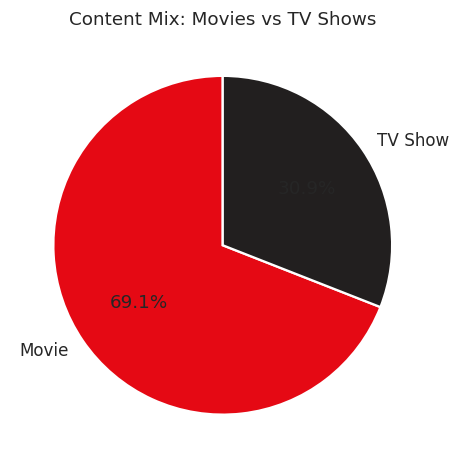

In [9]:
type_counts = df['type'].value_counts()
print(type_counts)
print(f"\nMovies make up {type_counts['Movie']/len(df)*100:.1f}% of the catalog")

plt.figure(figsize=(5,5))
plt.pie(type_counts, labels=type_counts.index, autopct='%1.1f%%',
        colors=['#E50914', '#221F1F'], startangle=90,
        wedgeprops={'edgecolor':'white','linewidth':1.5})
plt.title('Content Mix: Movies vs TV Shows')
plt.savefig('charts/01_type_split.png', bbox_inches='tight')
plt.show()


### 3.2 Catalog Growth Over Time

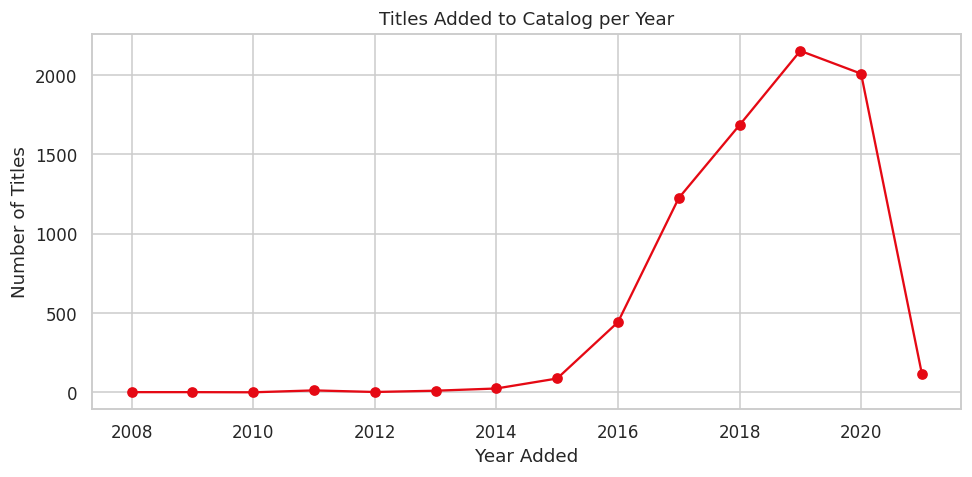

In [10]:
yearly = df.dropna(subset=['year_added']).groupby('year_added').size()

plt.figure(figsize=(9,4.5))
yearly.plot(kind='line', marker='o', color='#E50914')
plt.title('Titles Added to Catalog per Year')
plt.xlabel('Year Added'); plt.ylabel('Number of Titles')
plt.tight_layout()
plt.savefig('charts/02_yearly_growth.png', bbox_inches='tight')
plt.show()


**Note:** 2021 shows a sharp drop — the dataset was captured mid-2021, so that year is only partially represented. It should not be read as a real decline.

### 3.3 Top Genres

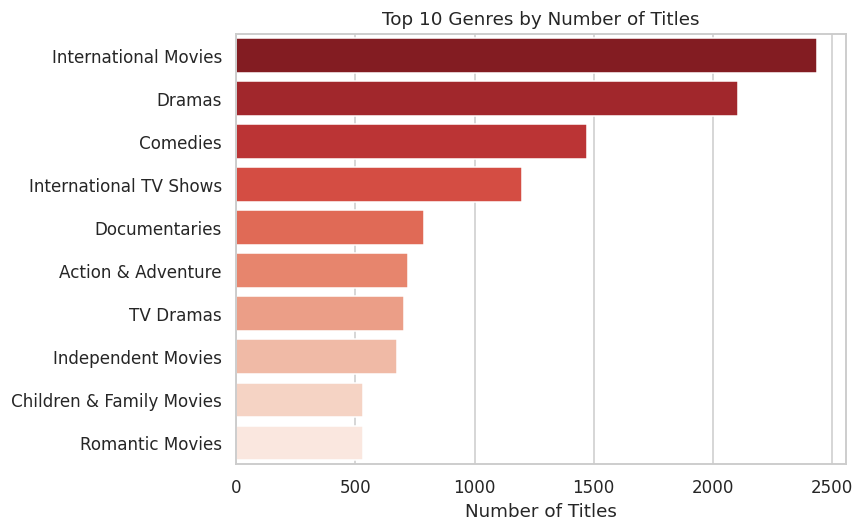

In [11]:
top_genres = genres['genre'].value_counts().head(10)

plt.figure(figsize=(8,5))
sns.barplot(x=top_genres.values, y=top_genres.index, hue=top_genres.index,
            palette='Reds_r', legend=False)
plt.title('Top 10 Genres by Number of Titles')
plt.xlabel('Number of Titles'); plt.ylabel('')
plt.tight_layout()
plt.savefig('charts/03_top_genres.png', bbox_inches='tight')
plt.show()


### 3.4 Top Content-Producing Countries

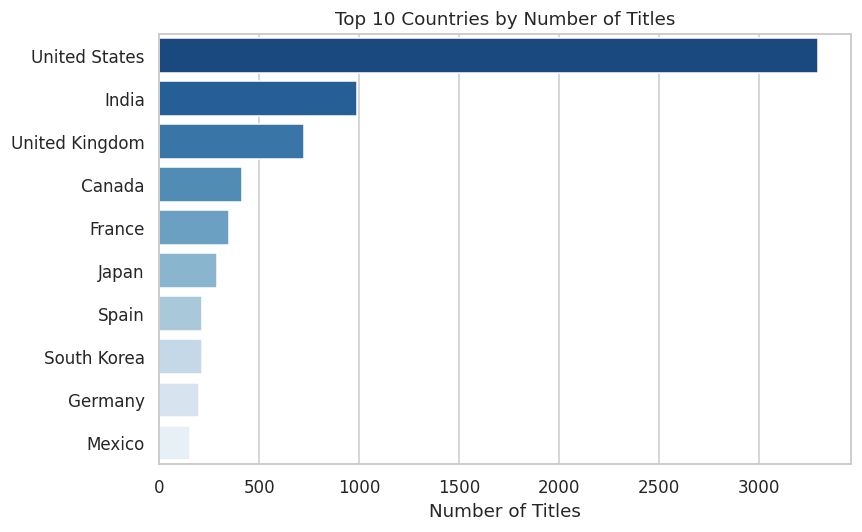

In [12]:
top_countries = countries['country_single'].value_counts().head(10)

plt.figure(figsize=(8,5))
sns.barplot(x=top_countries.values, y=top_countries.index, hue=top_countries.index,
            palette='Blues_r', legend=False)
plt.title('Top 10 Countries by Number of Titles')
plt.xlabel('Number of Titles'); plt.ylabel('')
plt.tight_layout()
plt.savefig('charts/04_top_countries.png', bbox_inches='tight')
plt.show()


### 3.5 Content Rating Distribution

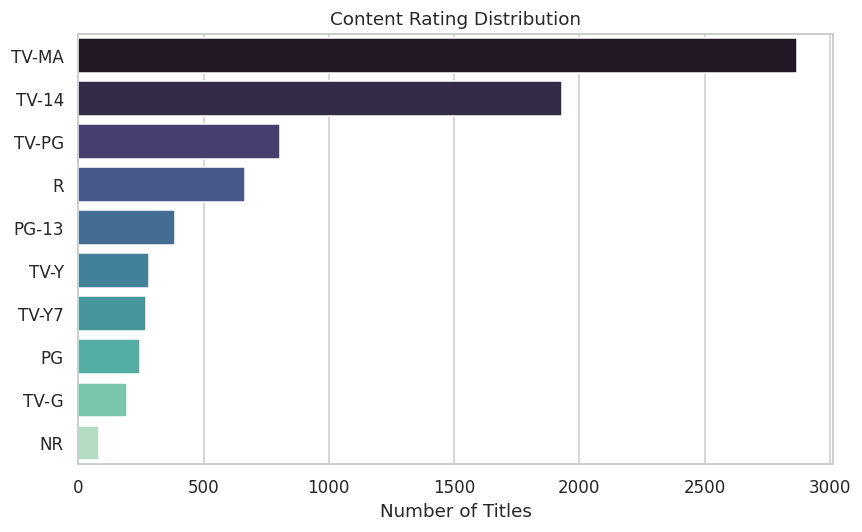

In [13]:
rating_counts = df['rating'].value_counts().head(10)

plt.figure(figsize=(8,5))
sns.barplot(x=rating_counts.values, y=rating_counts.index, hue=rating_counts.index,
            palette='mako', legend=False)
plt.title('Content Rating Distribution')
plt.xlabel('Number of Titles'); plt.ylabel('')
plt.tight_layout()
plt.savefig('charts/05_ratings.png', bbox_inches='tight')
plt.show()


### 3.6 Movie Duration Distribution

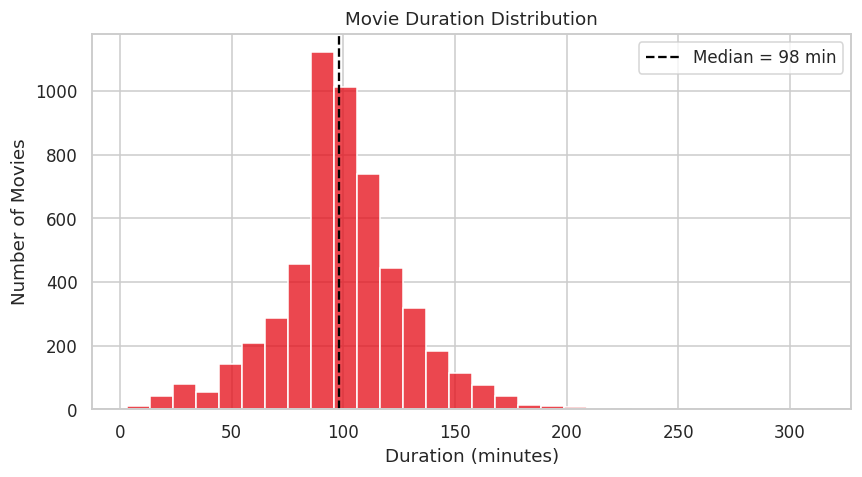

In [14]:
plt.figure(figsize=(8,4.5))
sns.histplot(df.loc[df['type']=='Movie', 'duration_minutes'].dropna(), bins=30, color='#E50914')
plt.axvline(df.loc[df['type']=='Movie','duration_minutes'].median(), color='black',
            linestyle='--', label=f"Median = {df.loc[df['type']=='Movie','duration_minutes'].median():.0f} min")
plt.title('Movie Duration Distribution')
plt.xlabel('Duration (minutes)'); plt.ylabel('Number of Movies')
plt.legend()
plt.tight_layout()
plt.savefig('charts/06_movie_duration.png', bbox_inches='tight')
plt.show()


### 3.7 When Is Content Added? (Seasonality)

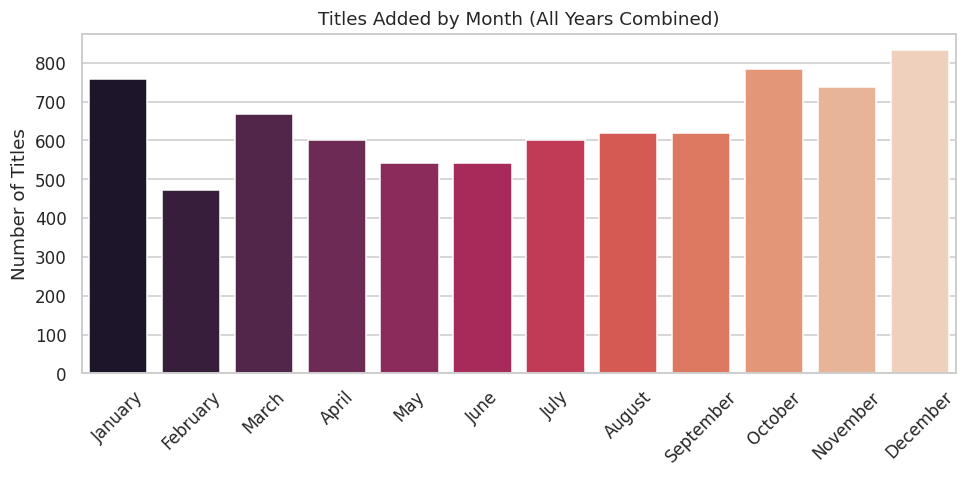

In [15]:
month_order = ['January','February','March','April','May','June',
               'July','August','September','October','November','December']
month_trend = df['month_added'].value_counts().reindex(month_order)

plt.figure(figsize=(9,4.5))
sns.barplot(x=month_trend.index, y=month_trend.values, hue=month_trend.index,
            palette='rocket', legend=False)
plt.title('Titles Added by Month (All Years Combined)')
plt.xlabel(''); plt.ylabel('Number of Titles')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('charts/07_month_trend.png', bbox_inches='tight')
plt.show()


## 4. SQL-Based Analysis

The same cleaned dataset is loaded into a SQLite database so the key business questions can be answered with SQL — demonstrating the query-writing skill directly, independent of pandas.

In [16]:
conn = sqlite3.connect(':memory:')
df.to_sql('netflix', conn, index=False, if_exists='replace')
print("Loaded", pd.read_sql("SELECT COUNT(*) AS row_count FROM netflix", conn).iloc[0,0], "rows into SQLite table `netflix`")


Loaded 7787 rows into SQLite table `netflix`


**Query 1 — Content growth by year (Movies vs TV Shows):**

In [17]:
query1 = '''
SELECT year_added,
       type,
       COUNT(*) AS titles_added
FROM netflix
WHERE year_added IS NOT NULL
GROUP BY year_added, type
ORDER BY year_added;
'''
pd.read_sql(query1, conn).tail(10)


,year_added,type,titles_added
14,2017.0,Movie,864
15,2017.0,TV Show,361
16,2018.0,Movie,1255
17,2018.0,TV Show,430
18,2019.0,Movie,1497
19,2019.0,TV Show,656
20,2020.0,Movie,1312
21,2020.0,TV Show,697
22,2021.0,Movie,88
23,2021.0,TV Show,29


**Query 2 — Top 5 content ratings by share of catalog:**

In [18]:
query2 = '''
SELECT rating,
       COUNT(*) AS title_count,
       ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM netflix), 1) AS pct_of_catalog
FROM netflix
GROUP BY rating
ORDER BY title_count DESC
LIMIT 5;
'''
pd.read_sql(query2, conn)


,rating,title_count,pct_of_catalog
0,TV-MA,2870,36.9
1,TV-14,1931,24.8
2,TV-PG,806,10.4
3,R,665,8.5
4,PG-13,386,5.0


**Query 3 — Longest-running TV shows (by season count):**

In [19]:
query3 = '''
SELECT title, country, seasons
FROM netflix
WHERE type = 'TV Show' AND seasons IS NOT NULL
ORDER BY seasons DESC
LIMIT 10;
'''
pd.read_sql(query3, conn)


,title,country,seasons
0,Grey's Anatomy,United States,16.0
1,NCIS,United States,15.0
2,Supernatural,"United States, Canada",15.0
3,COMEDIANS of the world,United States,13.0
4,Red vs. Blue,United States,13.0
5,Criminal Minds,"United States, Canada",12.0
6,Trailer Park Boys,Canada,12.0
7,Cheers,United States,11.0
8,Frasier,United States,11.0
9,Heartland,Canada,11.0


**Query 4 — Average movie runtime by decade of release (window into how film length has shifted):**

In [20]:
query4 = '''
SELECT (release_year / 10) * 10 AS decade,
       ROUND(AVG(duration_minutes), 1) AS avg_runtime_minutes,
       COUNT(*) AS movie_count
FROM netflix
WHERE type = 'Movie' AND duration_minutes IS NOT NULL
GROUP BY decade
ORDER BY decade;
'''
pd.read_sql(query4, conn)


,decade,avg_runtime_minutes,movie_count
0,1940,51.4,13
1,1950,107.1,11
2,1960,142.4,22
3,1970,119.1,63
4,1980,116.4,99
5,1990,113.9,194
6,2000,112.6,601
7,2010,96.8,3951
8,2020,89.5,423


**Query 5 — Which single country contributes the most TV-MA (mature) rated content?**

In [21]:
query5 = '''
SELECT country, COUNT(*) AS mature_titles
FROM netflix
WHERE rating = 'TV-MA' AND country != 'Unknown'
GROUP BY country
ORDER BY mature_titles DESC
LIMIT 5;
'''
pd.read_sql(query5, conn)


,country,mature_titles
0,United States,883
1,India,228
2,United Kingdom,168
3,Spain,109
4,South Korea,83


In [22]:
summary_tables = {
    'yearly_growth': pd.read_sql(query1, conn),
    'rating_share': pd.read_sql(query2, conn),
    'longest_running_shows': pd.read_sql(query3, conn),
    'runtime_by_decade': pd.read_sql(query4, conn),
}
for name, tbl in summary_tables.items():
    tbl.to_csv(f'exports/{name}.csv', index=False)
print("SQL summary tables exported to /exports for the Tableau dashboard.")


SQL summary tables exported to /exports for the Tableau dashboard.


## 5. Key Insights

- **Catalog is movie-heavy:** ~69% of titles are Movies vs ~31% TV Shows.
- **Explosive growth, then a plateau:** Titles added per year grew from low double digits (2014–15) to a peak of ~2,150 in 2019, before dipping slightly in 2020 — consistent with the broader industry slowdown in production during that period.
- **International content dominates the genre mix:** "International Movies" and "International TV Shows" are the single largest genre tags — this is a global, not US-only, catalog.
- **Geographic concentration:** The US supplies the largest single share of titles, but India, the UK, and Canada are strong secondary contributors — relevant for regional content strategy.
- **Mature content leads:** TV-MA is the single largest rating category, ahead of TV-14 — the catalog skews toward adult/mature audiences overall.
- **Movies cluster tightly around 90–115 minutes**, with a median around 98 minutes — useful as a benchmark when evaluating new content acquisitions.
- **Most TV shows are short-run (1 season)**, while a small number of long-running US shows (16+ seasons) are outliers — a classic long-tail content pattern.
- **Content additions peak in December, October, and January** — likely tied to holiday-season and awards-season release strategy.

## What I'd Build Next
- A Tableau dashboard on top of the exported summary tables (`/exports`) — combining the yearly trend, genre mix, and rating split into one interactive view.
- A simple recommendation/rating-prediction model using genre + rating + duration as features, to practice the ML side of data science.
